# Potomac River at Little Falls — USGS-01646500

This gauge watches the Potomac River at Little Falls, right where the river leaves Maryland and enters Washington, DC. Since March 1930, the USGS has measured how much water flows past this spot every single day. Everything that happens in the 11,560 square miles of land that drains into the river ends up in this one number.

It is one of the most watched gauges in the country, for a simple reason: **the water that passes Little Falls is the water the capital region drinks.**

Important facts:
* **Drinking water.** DC and the surrounding suburbs take about three-quarters of their water from the Potomac. The pumping station next to the gauge is part of the Washington Aqueduct. Below the gauge the river is "managed", because pipes pull water out of it, so Little Falls is the last honest look at how much water the basin actually produced.
* **Drought.** When the number here gets too low, the region starts releasing water from backup reservoirs and asks people to water their lawns less. The 2022 drought showed this: flows fell to near-record lows and restrictions followed.
* **Floods.** The same gauge is the early warning for big storms and ice jams. The huge flood of March 1936 (about as big as the 1889 one, which happened before the daily record begins) came through right here.

## Install and imports

In [37]:
%pip install dataretrieval # USGS package for data retrieval
%pip install matplotlib
%pip install geopandas
%pip install rhis-ts==0.2.0


[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
Looking in indexes: https://test.pypi.org/simple/, https://pypi.org/simple/

[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [38]:
from rhis_ts import Rhis
from dataretrieval import waterdata # https://waterdata.usgs.gov/?utm_source=chatgpt.com
from helpers import build_rhis_evol_df, build_repr_df
from plotting import plot_rhis_evolution # Helper function to plot the representative series along with their p-value evolutions

## Getting the data

The daily discharge record runs from March 1930 to today. Let's pull it and take a first look at how this river behaves.

In [39]:
# Get daily streamflow data (returns DataFrame and metadata)
df, metadata = waterdata.get_daily(
    monitoring_location_id="USGS-01646500",
    parameter_code="00060",  # Discharge
    time="1930-01-01/2026-10-28",
)

df.info()

Retrieving: daily · 1 page · 35,306 rows


<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 35306 entries, 0 to 35305
Data columns (total 12 columns):
 #   Column                  Non-Null Count  Dtype              
---  ------                  --------------  -----              
 0   geometry                35306 non-null  geometry           
 1   time_series_id          35306 non-null  str                
 2   monitoring_location_id  35306 non-null  str                
 3   parameter_code          35306 non-null  str                
 4   statistic_id            35306 non-null  str                
 5   time                    35306 non-null  datetime64[us]     
 6   value                   35306 non-null  float64            
 7   unit_of_measure         35306 non-null  str                
 8   approval_status         35306 non-null  str                
 9   qualifier               345 non-null    object             
 10  last_modified           35306 non-null  datetime64[us, UTC]
 11  daily_id                35306 non

In [40]:
df = df.set_index('time') # Set time as the dataframe index, so Rhis doesn't treat it as data to be analyzed
target_df = df[['value']].rename(columns={'value': 'flow'}).copy()
target_df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 35306 entries, 1930-03-01 to 2026-10-28
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   flow    35306 non-null  float64
dtypes: float64(1)
memory usage: 551.7 KB


## Exploratory analysis

Before running any statistical test, it pays to *look* at the data. This section answers five practical questions:

1. **Is the record complete?** Gaps and provisional values change what the tests "see".
2. **What does a typical flow look like?** The shape of the distribution explains why RHIS-TS uses non-parametric tests.
3. **Is there a seasonal cycle?** Seasons are the most common reason a streamflow series fails the randomness test.
4. **Does today's flow "remember" yesterday's?** This memory (persistence) is what the independence test detects.
5. **Are there long-term changes?** Shifts and trends are what the homogeneity and stationarity tests detect.

No knowledge of statistics is needed to follow along: every plot comes with a short "how to read it".

In [41]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Colors used in this section (one color per role, kept consistent across plots)
BLUE, ORANGE, AQUA = '#2a78d6', '#eb6834', '#1baf7a'
MUTED, GRID = '#52514e', '#e6e5e1'

flow = target_df['flow']  # daily mean discharge, ft³/s


def tidy(ax):
    """Light grid, no top/right frame: keeps the eye on the data."""
    ax.grid(color=GRID, linewidth=0.8)
    ax.spines[['top', 'right']].set_visible(False)
    ax.spines[['left', 'bottom']].set_color(MUTED)

### 0. A first look at the series

Before answering any question, let's simply plot the data. The top panel shows the whole daily record, almost a century of it. The bottom panel zooms in on the last three years, where you can see how the flow changes from day to day.

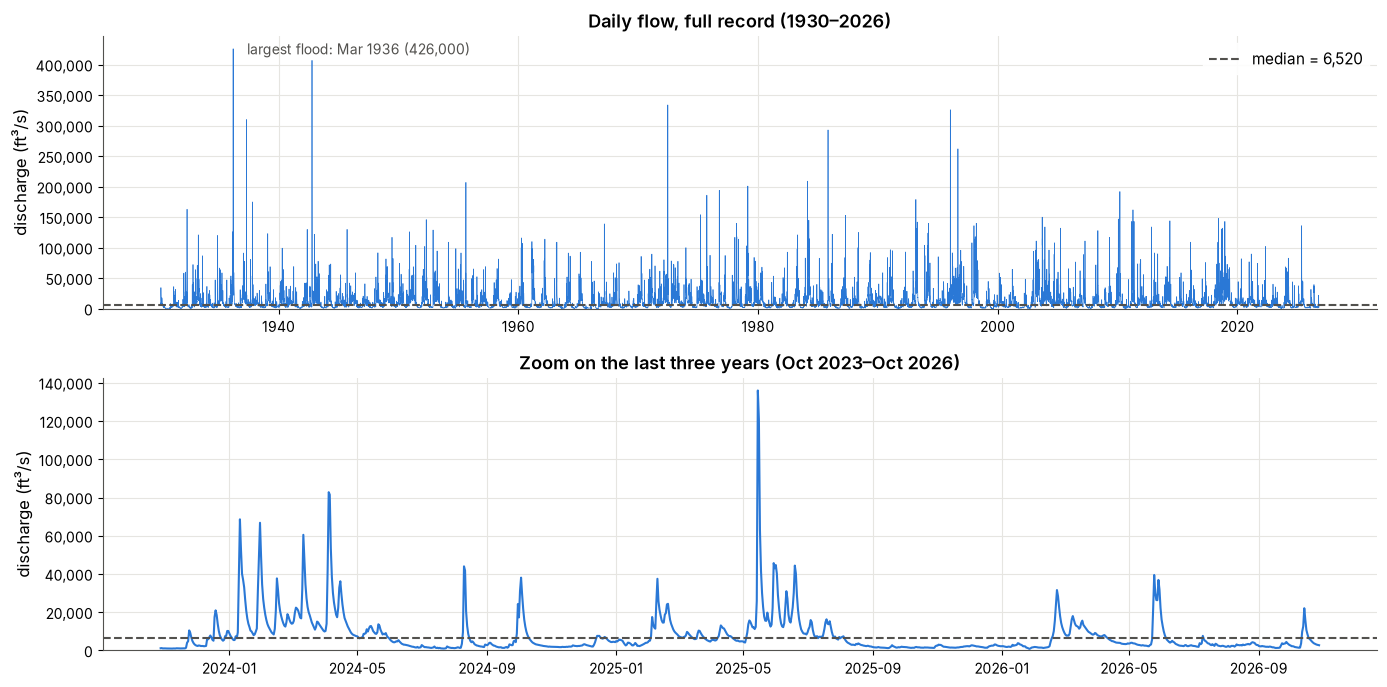

In [42]:
from matplotlib.ticker import StrMethodFormatter

recent = flow.loc[flow.index.max() - pd.DateOffset(years=3):]

fig, axes = plt.subplots(2, 1, figsize=(14, 7))

# Top: the full daily record, 1930 to today
axes[0].plot(flow.index, flow, color=BLUE, linewidth=0.5)
axes[0].axhline(flow.median(), color=MUTED, linestyle='--', linewidth=1.5, label=f'median = {flow.median():,.0f}')
axes[0].annotate(f'largest flood: {flow.idxmax():%b %Y} ({flow.max():,.0f})', (flow.idxmax(), flow.max()),
                 textcoords='offset points', xytext=(10, -4), color=MUTED, fontsize=10)
axes[0].set_title(f'Daily flow, full record ({flow.index.min():%Y}–{flow.index.max():%Y})')
axes[0].legend(loc='upper right')

# Bottom: the last three years, where the day-to-day texture is visible
axes[1].plot(recent.index, recent, color=BLUE, linewidth=1.5)
axes[1].axhline(flow.median(), color=MUTED, linestyle='--', linewidth=1.5)
axes[1].set_title(f'Zoom on the last three years ({recent.index.min():%b %Y}–{recent.index.max():%b %Y})')

for ax in axes:
    ax.set_ylabel('discharge (ft³/s)')
    ax.set_ylim(bottom=0)
    ax.yaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))
    tidy(ax)

plt.tight_layout()
plt.show()

**How to read it:** in the full record (top), the series looks like a dense band near the bottom with sharp spikes rising out of it. Each spike is a flood, and the March 1936 flood dwarfs everything else. Most days sit far below the spikes, near the dashed median line. The zoom (bottom) shows what that dense band really is: flows rise in winter and spring, fall to a low in late summer and fall, and change smoothly from one day to the next rather than jumping around at random.

These first impressions (a few huge floods, a yearly rhythm, smooth day-to-day changes) are exactly what the five questions below look at more closely.

### 1. Is the record complete?

Statistical tests read the values **in order** and do not know the dates. A missing day is simply skipped, so the test sees two days that were not really consecutive. Let's check how many days are missing and how many values are still *provisional* (recent data that USGS may still revise).

In [43]:
expected_days = pd.date_range(flow.index.min(), flow.index.max(), freq='D')
missing_days = expected_days.difference(flow.index)

print(f"First day:      {flow.index.min():%Y-%m-%d}")
print(f"Last day:       {flow.index.max():%Y-%m-%d}")
print(f"Days with data: {len(flow):,} of {len(expected_days):,} expected")
print(f"Missing days:   {len(missing_days):,} ({len(missing_days) / len(expected_days):.2%})")
print(f"Zero or negative flows: {(flow <= 0).sum()}")
print()
print("Approval status of the values:")
print(df['approval_status'].value_counts().to_string())

First day:      1930-03-01
Last day:       2026-10-28
Days with data: 35,306 of 35,306 expected
Missing days:   0 (0.00%)
Zero or negative flows: 0

Approval status of the values:
approval_status
Approved       35101
Provisional      205


**How to read it:** there are no missing days and no zero or negative flows, so gaps will not distort the tests. Provisional values cover only the most recent months; they are fine for exploration, but keep in mind that the **last few months may change** when USGS approves them — and RHIS-TS gives special weight to the most recent data.

Also note that the first and last years are **incomplete** (the record starts in March 1930 and ends in October 2026). An annual average computed from a partial year misses part of the seasonal cycle, so those two years are not comparable with the others.

### 2. What does a typical flow look like?

In [44]:
print(flow.describe(percentiles=[0.1, 0.5, 0.9]).round(0).to_string())
print()
print(f"Lowest daily flow:  {flow.min():,.0f} ft³/s on {flow.idxmin():%Y-%m-%d}")
print(f"Highest daily flow: {flow.max():,.0f} ft³/s on {flow.idxmax():%Y-%m-%d}")
print(f"The mean is {flow.mean() / flow.median():.1f}x the median")

count     35306.0
mean      11329.0
std       15832.0
min         121.0
10%        1700.0
50%        6520.0
90%       25300.0
max      426000.0

Lowest daily flow:  121 ft³/s on 1966-09-09
Highest daily flow: 426,000 ft³/s on 1936-03-19
The mean is 1.7x the median


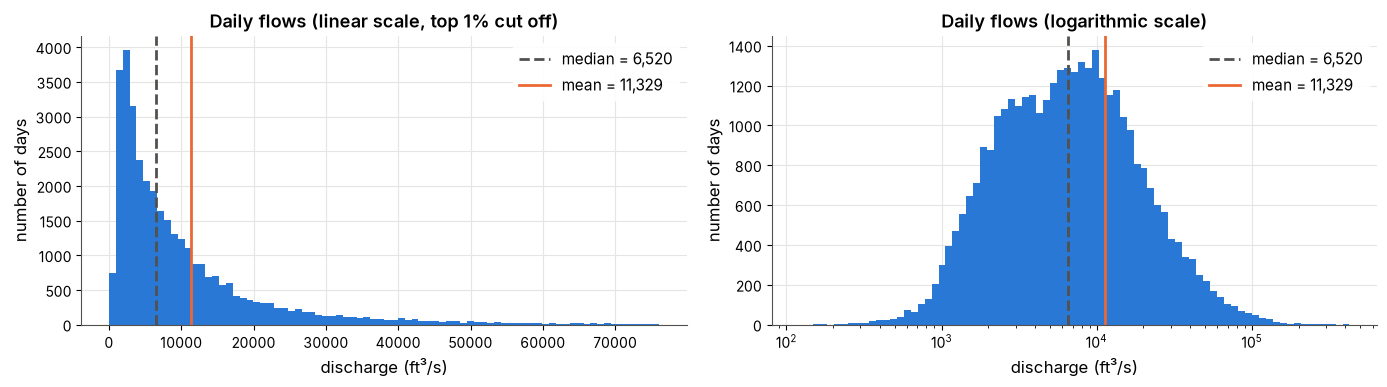

In [45]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].hist(flow, bins=80, range=(0, flow.quantile(0.99)), color=BLUE)
axes[0].set_title('Daily flows (linear scale, top 1% cut off)')

axes[1].hist(flow, bins=np.logspace(np.log10(flow[flow > 0].min()), np.log10(flow.max()), 80), color=BLUE)
axes[1].set_xscale('log')
axes[1].set_title('Daily flows (logarithmic scale)')

for ax in axes:
    ax.axvline(flow.median(), color=MUTED, linestyle='--', linewidth=2, label=f'median = {flow.median():,.0f}')
    ax.axvline(flow.mean(), color=ORANGE, linewidth=2, label=f'mean = {flow.mean():,.0f}')
    ax.set_xlabel('discharge (ft³/s)')
    ax.set_ylabel('number of days')
    ax.legend()
    tidy(ax)

plt.tight_layout()
plt.show()

**How to read it:** most days have modest flows, while a few flood days are many times larger, so the distribution has a long tail to the right (it is *skewed*). The floods pull the mean well above the median: the "average" flow is higher than what happens on a typical day. On a logarithmic scale (right), which compresses large values, the shape becomes roughly symmetric: a common trick hydrologists use to see low and high flows on the same plot.

**Why it matters:** many classical tests assume a bell-shaped (normal) distribution, which these data clearly do not follow. RHIS-TS uses **non-parametric** tests, which work with the order or rank of the values instead of their size, so skewness and floods are not a problem for them.

### 3. Is there a seasonal cycle?

Each box below summarizes the average flow of one calendar month across all years of the record (about 97 values per box).

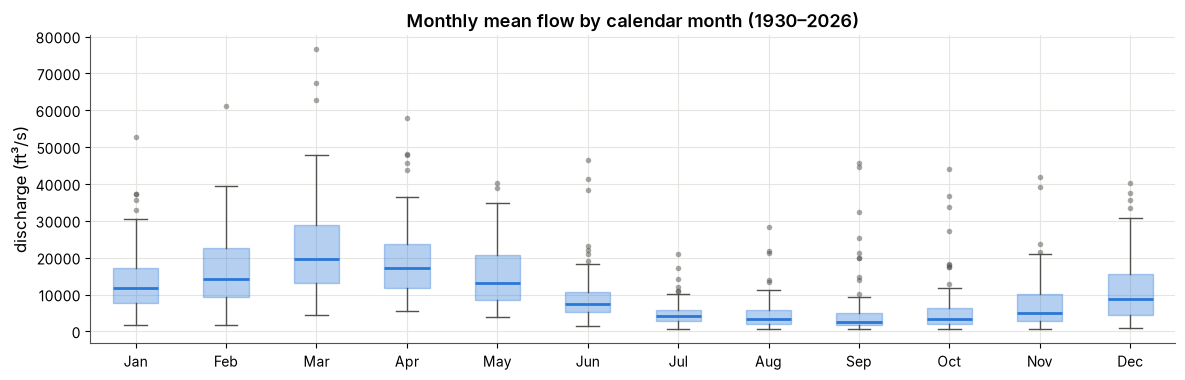

Wettest month (median): Mar (19,570 ft³/s)
Driest month (median):  Sep (2,502 ft³/s)
Ratio wettest/driest:   7.8x


In [46]:
monthly_mean = flow.resample('MS').mean()
by_month = [monthly_mean[monthly_mean.index.month == m].to_numpy() for m in range(1, 13)]
month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

fig, ax = plt.subplots(figsize=(14, 4))
ax.boxplot(
    by_month, tick_labels=month_names, widths=0.5, patch_artist=True,
    boxprops={'facecolor': BLUE, 'edgecolor': BLUE, 'alpha': 0.35},
    medianprops={'color': BLUE, 'linewidth': 2},
    whiskerprops={'color': MUTED}, capprops={'color': MUTED},
    flierprops={'marker': 'o', 'markersize': 4, 'markerfacecolor': MUTED, 'markeredgecolor': 'none', 'alpha': 0.5},
)
ax.set_title('Monthly mean flow by calendar month (1930–2026)')
ax.set_ylabel('discharge (ft³/s)')
tidy(ax)
plt.show()

medians = pd.Series([np.median(v) for v in by_month], index=month_names)
print(f"Wettest month (median): {medians.idxmax()} ({medians.max():,.0f} ft³/s)")
print(f"Driest month (median):  {medians.idxmin()} ({medians.min():,.0f} ft³/s)")
print(f"Ratio wettest/driest:   {medians.max() / medians.min():.1f}x")

**How to read it:** the line inside each box is the typical (median) flow of that month; the box holds the middle half of the years; the dots are unusual years. Flows are high in late winter and spring, when rain falls on wet soils and snow melts and the plants use little water, and low in late summer and early fall, when evaporation and plant water use are at their peak.

**Why it matters:** a series with a regular seasonal rise and fall is *not* random, because its ups and downs follow the calendar. The randomness test will reject it for that reason alone, which says nothing about whether the river has changed. That is why, later on, the seasonal cycle is removed (or the data are aggregated to annual values) before testing.

### 4. Does today's flow "remember" yesterday's?

If you know today's flow, you can make a good guess about tomorrow's: a river drains slowly, and groundwater keeps feeding it for weeks after a storm. Statisticians call this **persistence** or **autocorrelation**.

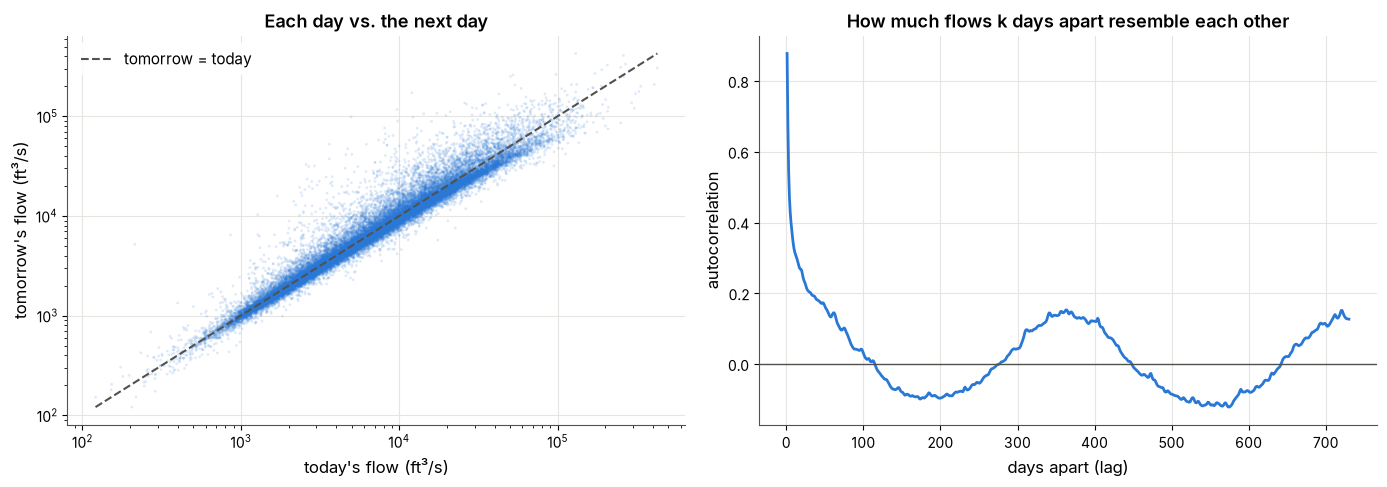

In [47]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: each dot is one day, plotted against the next day
axes[0].scatter(flow.iloc[:-1], flow.iloc[1:], s=4, color=BLUE, alpha=0.15, edgecolors='none')
lims = [flow[flow > 0].min(), flow.max()]
axes[0].plot(lims, lims, color=MUTED, linestyle='--', linewidth=1.5, label='tomorrow = today')
axes[0].set_xscale('log')
axes[0].set_yscale('log')
axes[0].set_xlabel("today's flow (ft³/s)")
axes[0].set_ylabel("tomorrow's flow (ft³/s)")
axes[0].set_title('Each day vs. the next day')
axes[0].legend()

# Right: how similar the series is to itself shifted by k days
lags = np.arange(1, 731)
acf = [flow.autocorr(k) for k in lags]
axes[1].plot(lags, acf, color=BLUE, linewidth=2)
axes[1].axhline(0, color=MUTED, linewidth=1)
axes[1].set_xlabel('days apart (lag)')
axes[1].set_ylabel('autocorrelation')
axes[1].set_title('How much flows k days apart resemble each other')

for ax in axes:
    tidy(ax)
plt.tight_layout()
plt.show()

**How to read it:**

* **Left:** the dots hug the dashed line, meaning tomorrow's flow is almost always close to today's. In a series without memory the dots would form a shapeless cloud.
* **Right:** autocorrelation measures how much the series resembles itself shifted by a number of days, from 1 (identical) to 0 (unrelated) to −1 (opposite). It starts near 0.9, drops quickly over the first days and then fades slowly over about three months — that is persistence. The gentle wave with peaks every 365 days is the seasonal cycle showing up again.

**Why it matters:** the independence test assumes each value tells you nothing about the next one. Daily flows break this assumption strongly, so they will fail the independence test almost regardless of the period chosen.

A common way to weaken persistence is to **aggregate** to longer time steps. The table below shows how the memory between consecutive values changes with the time step. The "monthly anomaly" is the monthly flow minus the typical flow for that calendar month, a simple way to remove the seasons.

In [48]:
monthly_anomaly = monthly_mean - monthly_mean.groupby(monthly_mean.index.month).transform('mean')
annual_mean = flow.resample('YS').mean()
complete_years = flow.resample('YS').count() >= 365
annual_complete = annual_mean[complete_years]

lag1 = pd.Series({
    'daily': flow.autocorr(1),
    'monthly': monthly_mean.autocorr(1),
    'monthly anomaly (seasons removed)': monthly_anomaly.autocorr(1),
    'annual (complete years)': annual_complete.autocorr(1),
})
n_values = pd.Series({
    'daily': len(flow),
    'monthly': len(monthly_mean),
    'monthly anomaly (seasons removed)': len(monthly_anomaly),
    'annual (complete years)': len(annual_complete),
})
# Rough threshold: below about 2/sqrt(n), the correlation is indistinguishable from chance
summary = pd.DataFrame({
    'lag-1 autocorrelation': lag1.round(2),
    'number of values': n_values,
    'chance level (±2/√n)': (2 / np.sqrt(n_values)).round(2),
})
summary

,lag-1 autocorrelation,number of values,chance level (±2/√n)
daily,0.88,35306,0.01
monthly,0.52,1160,0.06
monthly anomaly (seasons removed),0.38,1160,0.06
annual (complete years),0.08,95,0.21


**How to read it:** the closer the lag-1 autocorrelation is to 0, the weaker the memory between consecutive values. Memory is extreme for daily flows, still clear for monthly flows (partly due to the seasons), weaker but still present once the seasons are removed, and close to chance level for annual flows.

Note the last column: with many values, even a small correlation is statistically detectable. This is why the monthly anomalies can still fail the independence test even though their memory looks modest.

### 5. Are there long-term changes?

Annual averages smooth out the seasons and most of the persistence, which makes them the best scale to look for shifts and trends by eye.

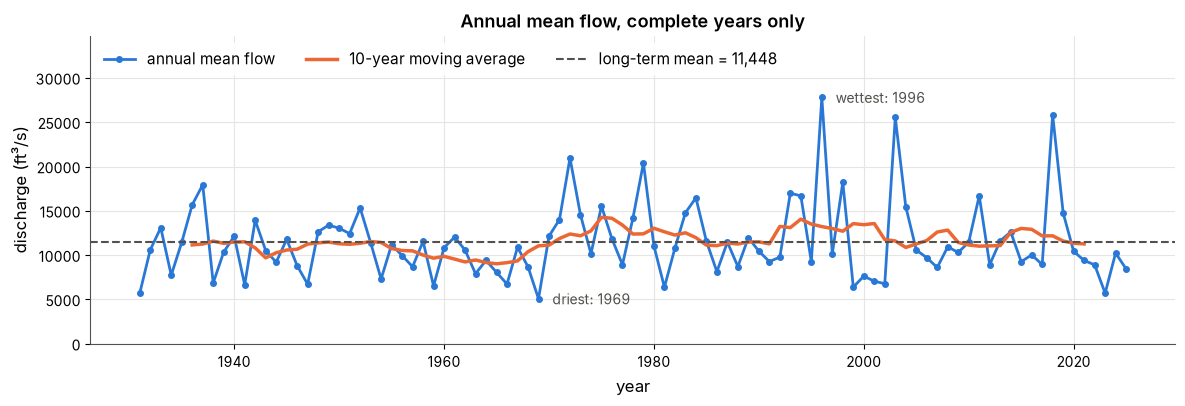

Mean of the first half (1931–1977):  10,870 ft³/s
Mean of the second half (1978–2025): 12,015 ft³/s


In [49]:
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(annual_complete.index.year, annual_complete, color=BLUE, linewidth=2, marker='o', markersize=4, label='annual mean flow')
rolling = annual_complete.rolling(10, center=True).mean()
ax.plot(rolling.index.year, rolling, color=ORANGE, linewidth=2.5, label='10-year moving average')
ax.axhline(annual_complete.mean(), color=MUTED, linestyle='--', linewidth=1.5, label=f'long-term mean = {annual_complete.mean():,.0f}')

for year, label in [(annual_complete.idxmax(), 'wettest'), (annual_complete.idxmin(), 'driest')]:
    ax.annotate(f'{label}: {year:%Y}', (year.year, annual_complete[year]), textcoords='offset points',
                xytext=(10, -4), color=MUTED, fontsize=10)

ax.set_ylim(0, annual_complete.max() * 1.25)  # headroom for the legend

ax.set_title('Annual mean flow, complete years only')
ax.set_xlabel('year')
ax.set_ylabel('discharge (ft³/s)')
ax.legend(loc='upper left', ncols=3)
tidy(ax)
plt.show()

first_half = annual_complete.iloc[:len(annual_complete) // 2]
second_half = annual_complete.iloc[len(annual_complete) // 2:]
print(f"Mean of the first half ({first_half.index[0]:%Y}–{first_half.index[-1]:%Y}):  {first_half.mean():,.0f} ft³/s")
print(f"Mean of the second half ({second_half.index[0]:%Y}–{second_half.index[-1]:%Y}): {second_half.mean():,.0f} ft³/s")

**How to read it:** the blue line jumps a lot from year to year (wet and dry years), while the orange 10-year moving average shows the slower behaviour: decades that were wetter or drier than the long-term mean. What matters for the homogeneity and stationarity tests is whether there is a lasting **step** (a shift to a new level) or a steady **slope** (a trend) — not ordinary wet and dry years. Judging by eye, there is a wetter stretch from the 1970s to around 2000, but flows return toward the long-term mean afterwards, without a clear step or slope. The second half of the record is about 10% wetter than the first: is that a real change or just natural variability? Answering that question is the job of the tests.

## What to expect from the RHIS tests

| What we saw | Assumption affected | Test | Expected outcome |
|---|---|---|---|
| Strong seasonal cycle (high in spring, low in late summer) | Randomness | Wallis-Moore | Rejected on daily and monthly data unless the seasons are removed |
| Strong day-to-day memory, weaker but present month to month | Independence | Wald-Wolfowitz | Rejected on daily data; possibly on monthly data, even after removing the seasons |
| No obvious step or slope in annual flows | Homogeneity, Stationarity | Mann-Whitney, Mann-Kendall | Likely not rejected on annual data |
| Skewed values with floods | — | all four | Not a problem: the tests use ranks, not raw values |

The next sections check these expectations on the data **as is** at three time steps (daily, monthly and annual), then on the two annual series that water managers use most: annual floods and annual low flows.

## How RHIS-TS reads a series

RHIS-TS answers one practical question: **how far back can I go and still treat the record as one consistent sample?**

It first tests the full record, then drops the oldest value and tests again, and so on until only the 8 most recent values are left. It reports the **longest stretch ending at the most recent value** that passes all four tests at the chosen significance level α (5% here). If not even the last 8 values pass, there is no compliant stretch.

Each result comes with a two-panel figure:

* **Top:** the series (grey dots) and, in black, the RHIS-compliant stretch, if there is one.
* **Bottom:** the p-value of each test. A point at date *t* is the p-value of the test applied to the stretch **from *t* to the end of the record**: the left edge is the full record, the right edge is the last 8 values. Points in the red band, below the dashed line (α), mean the test rejects that stretch. The thick grey line (RHIS-min) is the lowest of the four p-values; a stretch is compliant only when RHIS-min is above α.

The two helpers below run RHIS-TS on one series, print a plain-language summary, and draw this figure. They also collect every result for the summary table at the end.

In [50]:
ALPHA = 0.05  # significance level used throughout
HYPOTHESES = ['R', 'H', 'I', 'S']
results = {}  # one row per analyzed series, used in the summary table at the end


def fmt_p(p):
    """Readable p-value: very small values are shown as '<0.001'."""
    return '<0.001' if p < 0.001 else f'{p:.3f}'


def run_rhis(series, name, label, date_fmt='%Y-%m-%d'):
    """Run RHIS-TS on one series, print a summary, and store it in `results`."""
    rhis = Rhis(series.to_frame(name))
    start, end = rhis.get_repr_idxs(alpha=ALPHA)[name]
    rhis.build_rhis_evol_dict()
    evol_df = build_rhis_evol_df(rhis)
    repr_df = build_repr_df(rhis)

    index = rhis.numeric_orig_df.index
    full = evol_df[name].iloc[0]  # p-values of the four tests on the full record
    n = len(index)

    print(f'{label}: {n:,} values, {index[0]:{date_fmt}} to {index[-1]:{date_fmt}}')
    print('p-values on the full record: ' + ', '.join(f'{h} = {fmt_p(full[h])}' for h in HYPOTHESES))
    if end > start:
        stretch = f'{index[start]:{date_fmt}} to {index[end - 1]:{date_fmt}}'
        print(f'RHIS-compliant stretch: {stretch} ({end - start:,} values, {(end - start) / n:.0%} of the record)')
    else:
        stretch = 'none'
        print('RHIS-compliant stretch: none (even the last 8 values fail at least one test)')

    results[label] = {
        'values': n,
        **{f'{h} (full record)': fmt_p(full[h]) for h in HYPOTHESES},
        'compliant stretch': stretch,
        'compliant values': end - start,
        'share of record': f'{(end - start) / n:.0%}',
    }
    return rhis, evol_df, repr_df


def plot_evolution(rhis, evol_df, repr_df, title, last=None):
    """Plot the series and its p-value evolution. `last` limits the plot to the last N values."""
    window = slice(-last, None) if last else slice(None)
    plot_rhis_evolution(
        rhis.numeric_orig_df.iloc[window],
        evol_df.iloc[window], ALPHA,
        show_repr=True,
        save=False,
        repr_df=repr_df.iloc[window],
        figtitle=title,
        figsize=(12, 6),
    )

## 1. Daily flows

The daily record holds more than 35,000 values. With the seasonal cycle and the strong day-to-day memory seen above, randomness and independence are expected to fail. RHIS-TS tests every possible start date, so this cell takes a little while (about half a minute on a laptop).

In [51]:
rhis_d, evol_d, repr_d = run_rhis(flow, 'daily flow (ft³/s)', 'Daily flow')

Daily flow: 35,306 values, 1930-03-01 to 2026-10-28
p-values on the full record: R = <0.001, H = <0.001, I = <0.001, S = <0.001
RHIS-compliant stretch: none (even the last 8 values fail at least one test)


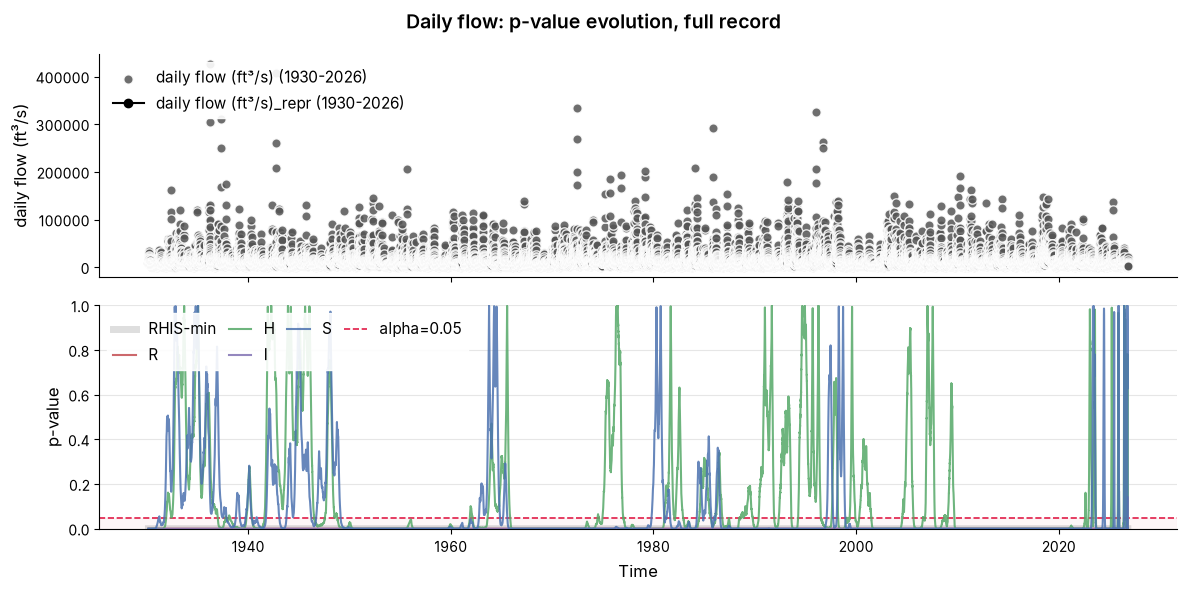

In [52]:
plot_evolution(rhis_d, evol_d, repr_d, 'Daily flow: p-value evolution, full record')

The full-record view squeezes 35,000 start dates into a few centimetres. Zooming on the last 120 days shows what happens to the shortest, most recent stretches:

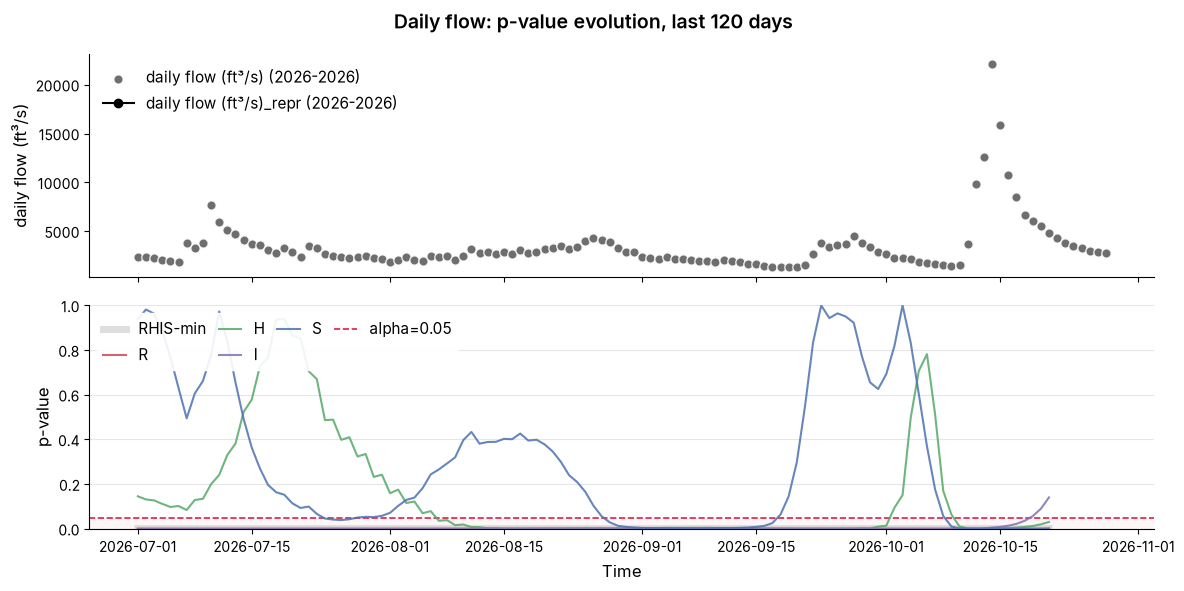

In [53]:
plot_evolution(rhis_d, evol_d, repr_d, 'Daily flow: p-value evolution, last 120 days', last=120)

**Result: no RHIS-compliant stretch.** All four tests reject the full record. Moving the start date forward never helps: randomness and independence stay below α for **every** start date, down to the last 8 days. Homogeneity and stationarity also reject the full record, which is surprising: at the monthly and annual scales (below) they pass easily. The next subsection explains why.

**What it means:** consecutive days are not separate pieces of information. A wet week is not seven independent observations; it is one storm seen seven times. Daily flows are the right input for hydrographs, flow-duration curves and reservoir operations, but **not** for any statistic that assumes independent values: return periods, confidence intervals, or the significance of a trend. For those, the daily record must first be summarized into values that are far enough apart.

### Why do homogeneity and stationarity reject the daily record?

On the full daily record, homogeneity (H) and stationarity (S) reject with p < 0.001: taken at face value, that says the river's flow shifted or trended over the century. Yet the same tests find nothing on monthly flows (p ≈ 0.46) or annual flows (p ≈ 0.83 and 0.93). Is the daily result a real change that the coarser scales miss, or a false alarm?

Two checks answer it. First, how big is the change the daily tests detect? Second, what happens to the p-values when the days used are far enough apart to stop "remembering" each other?

In [ ]:
from rhis_ts.hypothesis import mann_kendall, mann_whitney

half = len(flow) // 2
first, second = flow.iloc[:half], flow.iloc[half:]
print(f'Median daily flow {first.index[0]:%Y}–{first.index[-1]:%Y}: {first.median():,.0f} ft³/s')
print(f'Median daily flow {second.index[0]:%Y}–{second.index[-1]:%Y}: {second.median():,.0f} ft³/s ({second.median() / first.median() - 1:+.0%})')
print()

rows = []
for step in [1, 7, 30, 90, 365]:
    sample = flow.iloc[::step].to_numpy()  # keep one value every `step` days
    rows.append({
        'one value every': f'{step} day' + ('s' if step > 1 else ''),
        'values': len(sample),
        'H p-value': fmt_p(mann_whitney(sample).p_value),
        'S p-value': fmt_p(mann_kendall(sample).p_value),
    })
pd.DataFrame(rows).set_index('one value every')

Median daily flow 1930–1978: 6,340 ft³/s
Median daily flow 1978–2026: 6,730 ft³/s (+6%)



,values,H p-value,S p-value
one value every,,,
1 day,35306,<0.001,<0.001
7 days,5044,0.021,0.018
30 days,1177,0.390,0.332
90 days,393,0.559,0.641
365 days,97,0.440,0.779


**How to read it:** the median daily flow of the second half is only about 6% higher than the first: a small difference, well within the decade-to-decade swings seen in section 5. With every day used, both tests call it highly significant. Keeping only one day per week already raises the p-values a lot, and from one day per month on, both tests pass comfortably. The data are the same; only the spacing between values changed.

The decisive check is an experiment in which there is **no long-term change by construction**. Take the complete years, shuffle their order at random, and run the tests again. Each year stays intact, with its seasons and its day-to-day memory, but any real shift or trend across the century is destroyed. A well-behaved test at α = 5% should then reject about 5% of the time.

In [55]:
# Keep whole calendar years only, so that each year can be moved around as one block
whole_years = flow[flow.index.year.isin(annual_complete.index.year)]
daily_by_year = [year.to_numpy() for _, year in whole_years.groupby(whole_years.index.year)]
monthly_by_year = [year.resample('MS').mean().to_numpy() for _, year in whole_years.groupby(whole_years.index.year)]
annual_by_year = [year.mean() for year in daily_by_year]

rng = np.random.default_rng(0)
N_TRIALS = 500
false_alarms = {scale: {'H': 0, 'S': 0} for scale in ['daily', 'monthly', 'annual']}
for _ in range(N_TRIALS):
    order = rng.permutation(len(daily_by_year))  # a random order of the years: no long-term change by construction
    shuffled = {
        'daily': np.concatenate([daily_by_year[i] for i in order]),
        'monthly': np.concatenate([monthly_by_year[i] for i in order]),
        'annual': np.array([annual_by_year[i] for i in order]),
    }
    for scale, values in shuffled.items():
        false_alarms[scale]['H'] += mann_whitney(values).p_value < ALPHA
        false_alarms[scale]['S'] += mann_kendall(values).p_value < ALPHA

pd.DataFrame({
    scale: {
        'values per series': len(shuffled[scale]),
        'homogeneity (H) rejects': f"{counts['H'] / N_TRIALS:.0%}",
        'stationarity (S) rejects': f"{counts['S'] / N_TRIALS:.0%}",
        'should reject': f'{ALPHA:.0%}',
    }
    for scale, counts in false_alarms.items()
}).T

,values per series,homogeneity (H) rejects,stationarity (S) rejects,should reject
daily,34699,71%,72%,5%
monthly,1140,17%,17%,5%
annual,95,5%,6%,5%


**How to read it:** on annual values the tests behave as designed: about 5% false alarms. On monthly values they already raise false alarms about three times too often. On daily values they reject in about 7 shuffles out of 10, even though nothing changed.

**So yes: on daily data, the H and S rejections are not reliable evidence of a shift or trend, and are most likely a false alarm.** The cause is the lack of independence, mainly the river's persistence, plus the seasonal cycle that makes days of the same season alike. Both tests assume every value is a new, independent piece of information. Consecutive days are not, so 35,000 days carry far less information than 35,000 independent values would. The tests therefore underestimate how much the result could vary by chance, and a small difference, such as the 6% shift in the median, looks highly significant. The very large sample makes this worse, because the tests treat more data as more confidence.

**Practical rule:** read the H and S p-values only on a series where independence (I) passes. When independence fails, as on daily and monthly flows, a rejection of H or S may simply be the series' memory. Ask whether the trend or shift is still there on an independent series, such as annual values. Here it is not.

## 2. Monthly flows

Averaging over a month removes most of the day-to-day memory, but the seasons remain: every spring is wet and every late summer is dry.

Monthly flow: 1,160 values, 1930-03 to 2026-10
p-values on the full record: R = <0.001, H = 0.466, I = <0.001, S = 0.459
RHIS-compliant stretch: 2025-11 to 2026-10 (12 values, 1% of the record)


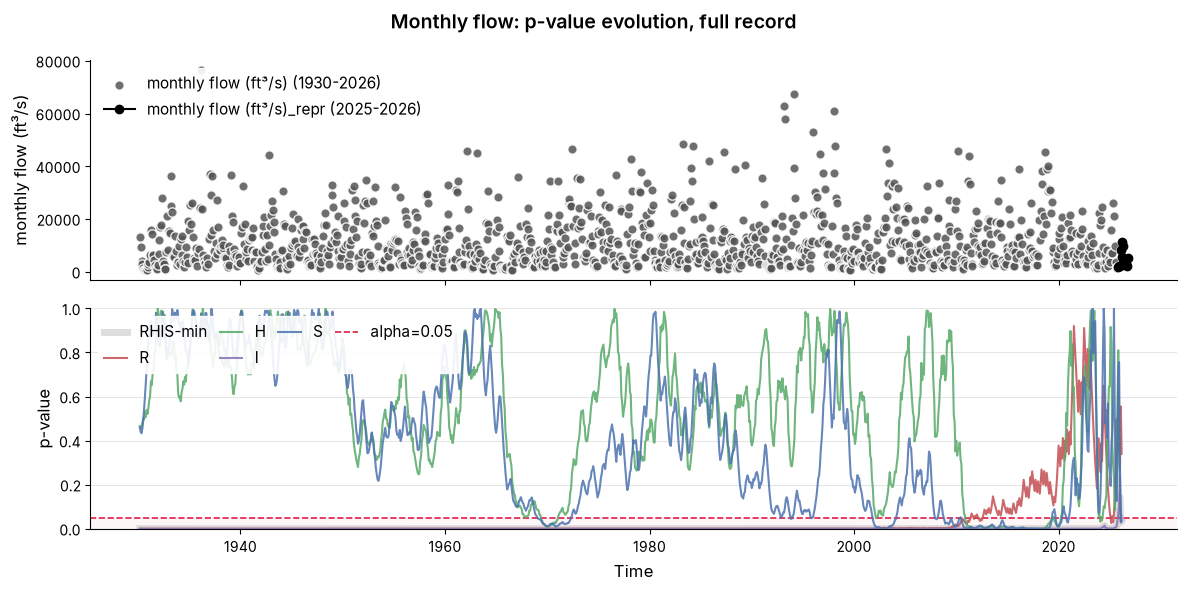

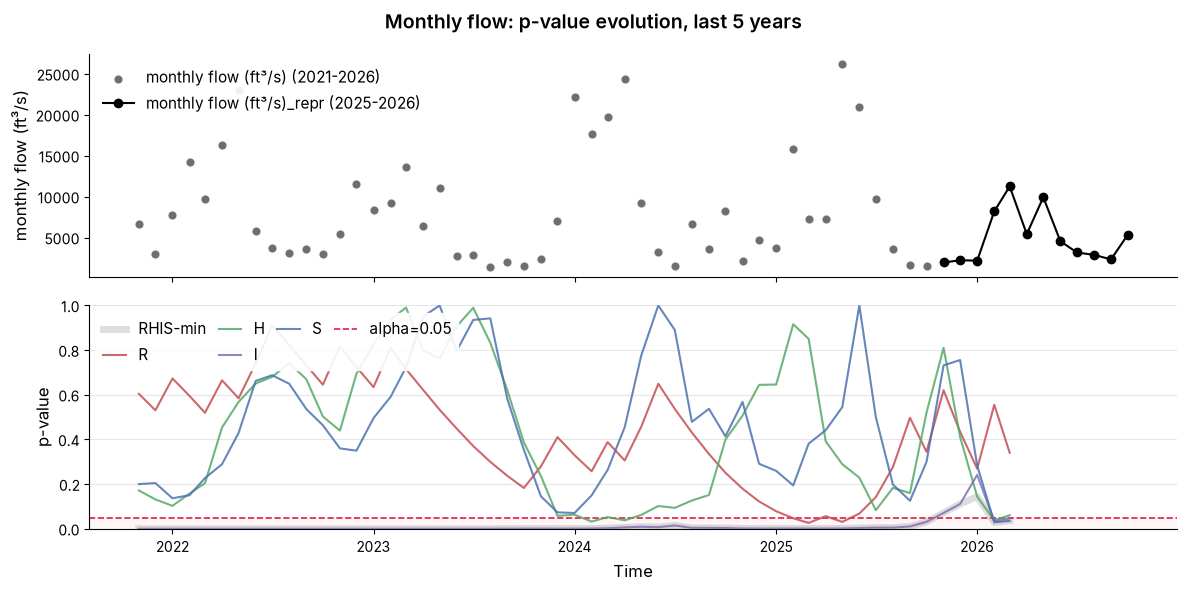

In [56]:
rhis_m, evol_m, repr_m = run_rhis(monthly_mean, 'monthly flow (ft³/s)', 'Monthly flow', date_fmt='%Y-%m')
plot_evolution(rhis_m, evol_m, repr_m, 'Monthly flow: p-value evolution, full record')
plot_evolution(rhis_m, evol_m, repr_m, 'Monthly flow: p-value evolution, last 5 years', last=60)

**Result: only the last 12 months pass.** On the full record, homogeneity and stationarity pass comfortably: there is no sign that the river's level shifted or drifted over the century. Randomness and independence are rejected, as expected from the seasons and the month-to-month memory. Independence is the test that blocks: it stays below α for almost every start date and only rises above it when the stretch is down to about a year.

**Be careful with this kind of result.** A 12-value stretch that passes is **weak evidence**: with so few values the tests have very little power to detect anything. Those 12 months are also a single seasonal cycle, they include values USGS still marks as provisional (from April 2026), and the last month (October 2026) is incomplete. One year cannot represent the wet and dry years a river goes through, so this stretch is **not** a representative sample of Potomac flows.

This is the most important caution when reading RHIS-TS results: a compliant stretch means *"the data do not give enough evidence to reject the assumptions"*, not *"this stretch is representative"*. **Always look at its length.**

### Does removing the seasons fix it?

The "monthly anomaly" from section 4 of the exploration is each month's flow minus the average flow for that calendar month: a simple way to remove the seasonal cycle.

Monthly anomaly (seasons removed): 1,160 values, 1930-03 to 2026-10
p-values on the full record: R = <0.001, H = 0.278, I = <0.001, S = 0.289
RHIS-compliant stretch: none (even the last 8 values fail at least one test)


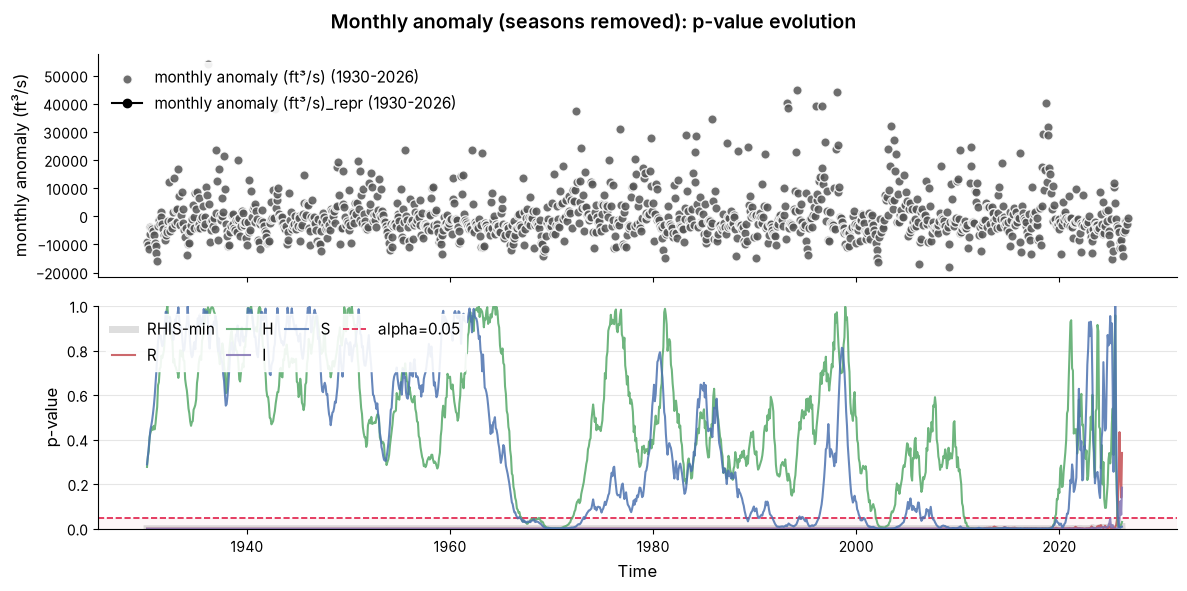

In [57]:
rhis_a, evol_a, repr_a = run_rhis(monthly_anomaly, 'monthly anomaly (ft³/s)', 'Monthly anomaly (seasons removed)', date_fmt='%Y-%m')
plot_evolution(rhis_a, evol_a, repr_a, 'Monthly anomaly (seasons removed): p-value evolution')

**Result: no compliant stretch at all**, not even the last year. Removing the average seasonal cycle does not remove the memory: a wetter-than-usual month tends to be followed by another one, because groundwater and soils drain slowly (the lag-1 autocorrelation of 0.38 measured in section 4). Randomness and independence still fail for nearly every start date.

**What it means:** subtracting monthly means is not enough to turn monthly flows into independent values. Monthly analyses, such as reservoir simulation or synthetic streamflow generation, need models that explicitly represent both the seasons and the memory, rather than treating months as a simple sample.

## 3. Annual flows

As in section 5 of the exploration, only complete years (1931–2025) are used: the partial years 1930 and 2026 would mix in a different share of wet and dry months.

Annual mean flow: 95 values, 1931 to 2025
p-values on the full record: R = 0.219, H = 0.832, I = 0.207, S = 0.933
RHIS-compliant stretch: 1931 to 2025 (95 values, 100% of the record)


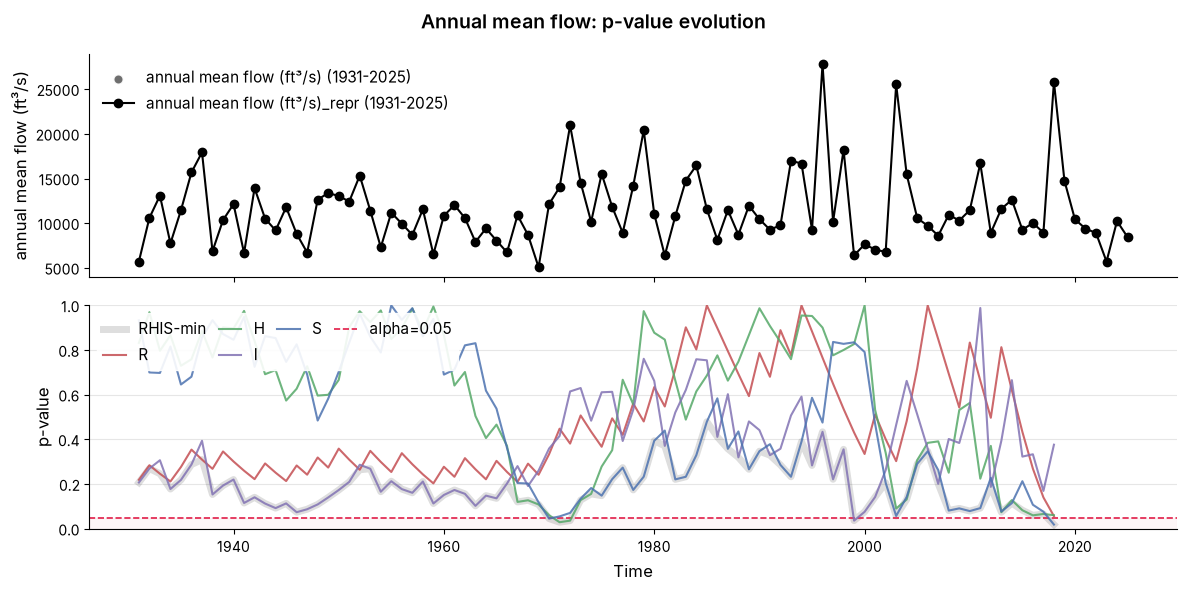

In [58]:
rhis_y, evol_y, repr_y = run_rhis(annual_complete, 'annual mean flow (ft³/s)', 'Annual mean flow', date_fmt='%Y')
plot_evolution(rhis_y, evol_y, repr_y, 'Annual mean flow: p-value evolution')

**Result: the whole record, 95 years, is RHIS-compliant.** None of the four p-values on the full record is close to α (the lowest, independence, is about 0.2). In the bottom panel, RHIS-min stays above α for almost every start date. It dips below α only for a few start years (1970–1972 and 1999) and for the shortest stretch, 2018–2025. That last one is a good lesson about short windows: 2018 was one of the three wettest years on record (about 25,800 ft³/s), so 8 values that begin with it look like a downward trend even though the years that follow are ordinary.

**What it means:** at the annual scale, the data show no evidence of a shift, a trend, or memory between years. The ~10% wetter second half seen in section 5 is not statistically significant. The full 95 years can be used as one sample, and the longer the sample, the smaller the uncertainty of anything estimated from it.

## 4. Floods and low flows: the annual extremes

Water managers rarely design with the annual mean. Two annual series are used far more often:

* **Annual maximum flow:** the largest flow of each year. It feeds **flood-frequency analysis**: the "100-year flood" used to design bridges, levees and floodplain maps.
* **Annual 7-day minimum flow:** the lowest 7-day average flow of each year. It feeds the **7Q10**, the 7-day low flow expected once every 10 years on average. Across the US, the 7Q10 is used to set wastewater discharge permits and to check whether water supply intakes stay reliable during droughts.

Here the annual maximum is the largest **daily mean** flow. Official USGS flood statistics use instantaneous peaks, which are higher, but the series behave alike for this purpose.

Annual maximum flow: 95 values, 1931 to 2025
p-values on the full record: R = 1.000, H = 0.561, I = 0.663, S = 0.969
RHIS-compliant stretch: 1931 to 2025 (95 values, 100% of the record)


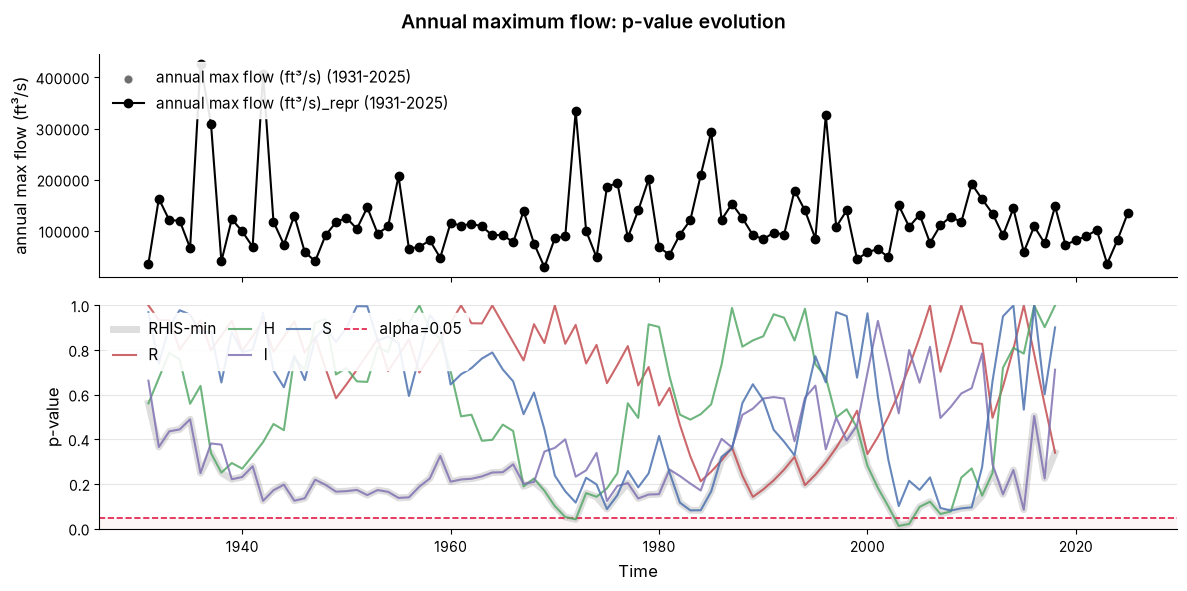

In [59]:
annual_max = flow.resample('YS').max()[complete_years]
annual_min7 = flow.rolling(7).mean().resample('YS').min()[complete_years]  # lowest 7-day average of each year

rhis_max, evol_max, repr_max = run_rhis(annual_max, 'annual max flow (ft³/s)', 'Annual maximum flow', date_fmt='%Y')
plot_evolution(rhis_max, evol_max, repr_max, 'Annual maximum flow: p-value evolution')

Annual 7-day minimum flow: 95 values, 1931 to 2025
p-values on the full record: R = 0.461, H = 0.777, I = 0.718, S = 0.819
RHIS-compliant stretch: 1931 to 2025 (95 values, 100% of the record)


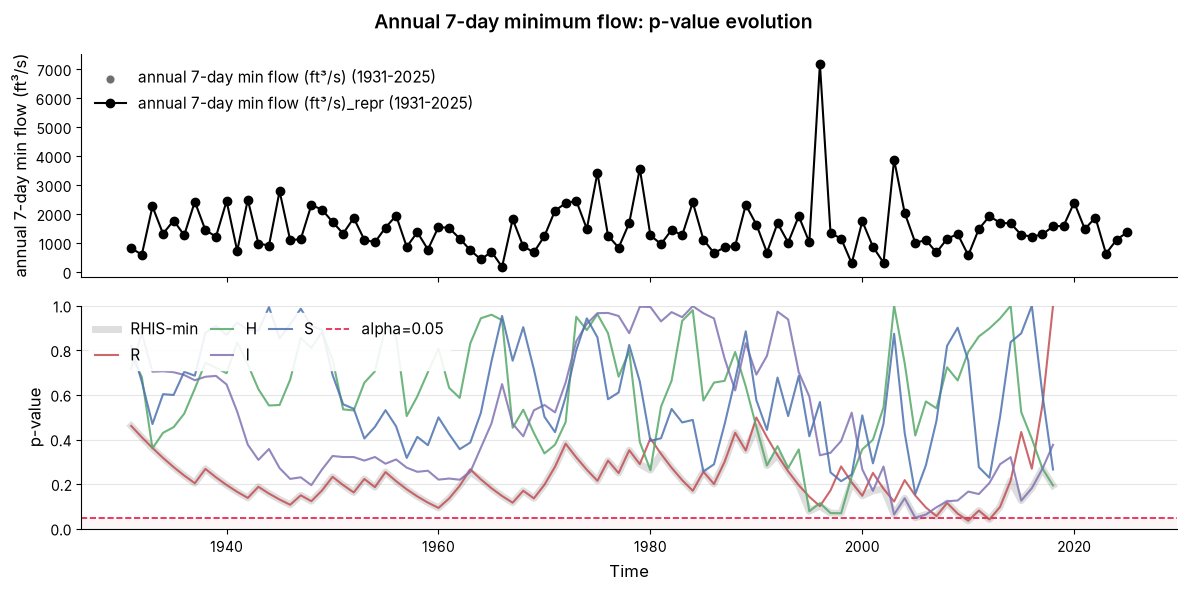

In [60]:
rhis_min7, evol_min7, repr_min7 = run_rhis(annual_min7, 'annual 7-day min flow (ft³/s)', 'Annual 7-day minimum flow', date_fmt='%Y')
plot_evolution(rhis_min7, evol_min7, repr_min7, 'Annual 7-day minimum flow: p-value evolution')

**Result: both extreme series are RHIS-compliant over the whole record (1931–2025).** All four tests pass on the full record with wide margins. Floods and droughts at Little Falls show no evidence of becoming larger or smaller, or of clustering in time, over the last 95 years.

## 5. Why it matters: how much of the record to use

A common practice is to use only a recent window, often the last 30 years, because older data feel "outdated". RHIS-TS replaces that feeling with evidence: here, the data give no reason to drop the older years.

To see what is at stake, let's estimate the two design values from section 4 using three samples: the full RHIS-compliant record, the last 30 years, and the first 30 years. The estimates use the log-Pearson type III distribution, the standard US choice for both floods and the 7Q10. The **90% range** comes from bootstrap resampling: the estimate is recomputed 2,000 times on random re-draws of the same years. That range shows how much the result depends on which years happened to be observed.

In [61]:
from scipy import stats


def lp3_quantile(values, prob):
    """Log-Pearson type III quantile, fitted by the method of moments on log10 values."""
    logs = np.log10(values)
    return 10 ** stats.pearson3.ppf(prob, stats.skew(logs, bias=False), loc=logs.mean(), scale=logs.std(ddof=1))


def estimate(values, prob, n_boot=2000, seed=42):
    """Estimate plus a 90% bootstrap range."""
    rng = np.random.default_rng(seed)
    values = np.asarray(values)
    boot = [lp3_quantile(rng.choice(values, len(values)), prob) for _ in range(n_boot)]
    low, high = np.percentile(boot, [5, 95])
    return lp3_quantile(values, prob), low, high


rows = []
for design_value, series, prob in [('100-year flood', annual_max, 0.99), ('7Q10 low flow', annual_min7, 0.10)]:
    samples = {
        'full record (RHIS-compliant)': series,
        'last 30 years': series.iloc[-30:],
        'first 30 years': series.iloc[:30],
    }
    for sample_name, sample in samples.items():
        value, low, high = estimate(sample, prob)
        rows.append({
            'design value': design_value,
            'sample': f'{sample_name}, {sample.index[0]:%Y}–{sample.index[-1]:%Y}',
            'estimate (ft³/s)': f'{value:,.0f}',
            '90% range (ft³/s)': f'{low:,.0f} – {high:,.0f}',
            'range width / estimate': f'{(high - low) / value:.0%}',
        })

pd.DataFrame(rows).set_index(['design value', 'sample'])

estimate (ft³/s)  \
design value   sample                                                     
100-year flood full record (RHIS-compliant), 1931–2025          383,466   
               last 30 years, 1996–2025                         292,851   
               first 30 years, 1931–1960                        548,137   
7Q10 low flow  full record (RHIS-compliant), 1931–2025              630   
               last 30 years, 1996–2025                             584   
               first 30 years, 1931–1960                            819   

                                                        90% range (ft³/s)  \
design value   sample                                                       
100-year flood full record (RHIS-compliant), 1931–2025  280,633 – 484,569   
               last 30 years, 1996–2025                 188,376 – 428,655   
               first 30 years, 1931–1960                266,136 – 805,242   
7Q10 low flow  full record (RHIS-compliant), 1931–2025          540 – 762   
               last 30 years, 1996–2025                         447 – 851   
               first 30 years, 1931–1960                        718 – 969   

                                                       range width / estimate  
design value   sample                                                          
100-year flood full record (RHIS-compliant), 1931–2025                    53%  
               last 30 years, 1996–2025                                   82%  
               first 30 years, 1931–1960                                  98%  
7Q10 low flow  full record (RHIS-compliant), 1931–2025                    35%  
               last 30 years, 1996–2025                                   69%  
               first 30 years, 1931–1960                                  31%

**How to read it:**

* **The window choice alone changes the answer by almost a factor of two.** The last 30 years give a 100-year flood of roughly 290,000 ft³/s; the first 30 years give roughly 550,000 ft³/s. The tests found no evidence that the flood regime changed, so this gap is mostly the luck of the draw: the first 30 years happen to contain three of the five largest floods on record (1936, 1937 and 1942). The 7Q10 shows the same effect on the low-flow side: about 580 ft³/s from the last 30 years against about 820 ft³/s from the first 30.
* **The full record gives the most reliable estimate.** For the 100-year flood, its 90% range is about half the estimate wide, against 80–100% for the 30-year windows. A narrow range alone is not enough, though: the first 30 years give a narrow 7Q10 range, yet their whole range lies above the full-record range. That estimate looks precise but rests on a run of wetter decades. For a 7Q10 that sets how much wastewater a plant may release, or a design flood that sizes a bridge, these differences are real money and real risk.
* **This is justified *because* RHIS-TS passed.** Using all the data is not automatically right. If the tests had found a break, for example after a dam was built or a large withdrawal began, the compliant stretch would have started after it, and RHIS-TS would have shown where.

*Note:* the fit here is deliberately simple (method of moments, skew from this gauge only) to illustrate the effect of sample choice. Official US flood studies follow Bulletin 17C, which adds regional skew and historical flood information.

## Summary of results

In [62]:
pd.DataFrame(results).T

,values,R (full record),H (full record),I (full record),S (full record),compliant stretch,compliant values,share of record
Daily flow,35306,<0.001,<0.001,<0.001,<0.001,none,0,0%
Monthly flow,1160,<0.001,0.466,<0.001,0.459,2025-11 to 2026-10,12,1%
Monthly anomaly (seasons removed),1160,<0.001,0.278,<0.001,0.289,none,0,0%
Annual mean flow,95,0.219,0.832,0.207,0.933,1931 to 2025,95,100%
Annual maximum flow,95,1.000,0.561,0.663,0.969,1931 to 2025,95,100%
Annual 7-day minimum flow,95,0.461,0.777,0.718,0.819,1931 to 2025,95,100%


## Conclusions and implications for water resources management

**Expected vs. observed**

| Series | Expected | Observed |
|---|---|---|
| Daily flow | Randomness and independence rejected | No compliant stretch, not even the last 8 days; homogeneity and stationarity also rejected, but as a false alarm caused by persistence |
| Monthly flow | Randomness and independence rejected | Only the last 12 months pass: too short to be representative |
| Monthly anomaly (seasons removed) | Independence possibly still rejected | No compliant stretch: month-to-month memory remains |
| Annual mean flow | Homogeneity and stationarity not rejected | The whole record (95 years) passes |
| Annual maximum and 7-day minimum | — | The whole record (95 years) passes |

**Main conclusions**

1. **The time step decides the answer.** The same river and the same data give no compliant stretch at the daily scale, one year at the monthly scale, and the full 95 years at the annual scale. A RHIS-TS result should always be reported together with its time step and its length.
2. **Daily and monthly rejections are expected and informative, not a data problem.** They measure the seasonal cycle and the river's memory. The practical consequence is to avoid computing return periods, confidence intervals or trend significance on daily or monthly values as if they were independent. Use annual series for frequency analysis, and models that represent seasons and memory for monthly or daily simulation.
3. **When independence fails, homogeneity and stationarity rejections cannot be trusted.** On daily flows, H and S reject the full record, yet the same tests reject in about 7 out of 10 shuffled records that contain no change at all. A "trend" found in persistent data must be confirmed on an independent series, such as annual values, before it is used to justify a decision, such as discarding old data or adjusting a design value.
4. **A short compliant stretch is a warning, not an answer.** Twelve values that pass the tests cannot support any frequency analysis. When RHIS-TS returns a short stretch, look at the p-value evolution to understand which test blocks and why.
5. **For the series that drive design (annual means, floods and low flows), the full record is a valid sample.** That gives design values with the smallest uncertainty. Picking an arbitrary window instead can move a 100-year flood or a 7Q10 by tens of percent without any physical reason.
6. **Re-run the tests as new data arrive.** On annual series RHIS-TS takes milliseconds, so it is cheap to repeat every year. If a change in climate, land use or water use starts to show up in the recent record, the compliant stretch will shorten, and the p-value evolution will show when the change began. The 2026 values should be checked again once USGS approves them.

**Limits to keep in mind.** Not rejecting an assumption does not prove it is true: with few values, the tests can miss real changes. RHIS-TS describes the *record*; it does not predict the future. For long planning horizons, combine it with other evidence, such as nearby gauges, known changes in the basin, and climate projections.